# SAE "Analyse automatique de données" -- Notebook 2 : classification binaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du classifieur choisi (k plus proche voisin ou arbre de décision) pour effectuer une classification binaire des avis ;
2. [Bonus] Effectuer des expérimentations supplémentaires avec d'autres classifieurs (l'autre classifieur vu en cours ou d'autres classifieurs de `scikit-learn`) ;
3. Rédiger une synthèse pour justifier des pré-traitements effectués, du choix du regroupement des notes pour obtenir des classes binaires et des valeurs des paramètres obtenus pour vos classifieurs. Vous concluerez sur le meilleur choix des pré-traitements, des classes binaires et des paramètres de votre ou vos classifieurs.


Faites attention à la prise en compte du déséquilibre que vous pourriez avoir entre vos deux classes, en termes de nombre d'avis dans chacune des classes. 
Vous pouvez notamment utiliser le module python `imbalanced-learn` pour tester différentes manières de gérer les déséquilibres entre classes.
	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.



## Modules python utilisés

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import spacy 
import numpy as np

## 1. Classification binaire avec le classifieur ...

Processeur : passthrough
Les meilleurs paramètres à utiliser sont :  {'classifier__criterion': 'entropy', 'classifier__max_depth': 20, 'classifier__min_samples_split': 15, 'classifier__splitter': 'best'}
Meilleur score de validation : 0.60946 
Rapport de classification pour DecisionTree 
                    precision    recall  f1-score   support

Avis défavorables       0.58      0.71      0.64       792
  Avis favorables       0.62      0.49      0.55       789

         accuracy                           0.60      1581
        macro avg       0.60      0.60      0.59      1581
     weighted avg       0.60      0.60      0.59      1581



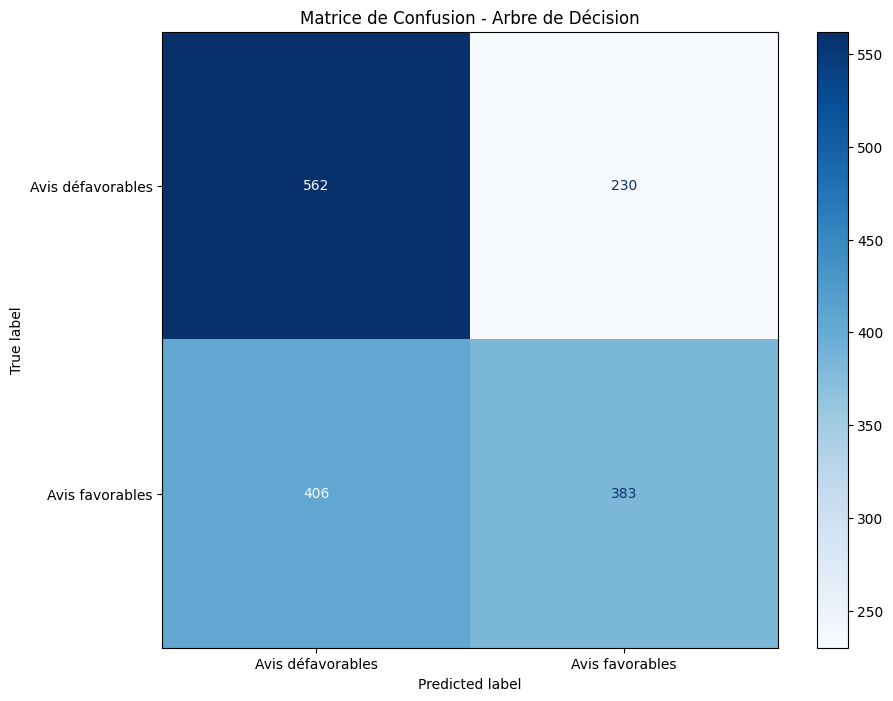

In [4]:
# --- Récupération des données du notebook 1 ---

#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)

# -------- Utilisation de Spacy / Formatage des données --------

x_train = x_train.dropna(subset=['text_']).copy()
y_train = y_train.loc[x_train.index].copy()

x_test = x_test.dropna(subset=['text_']).copy()
y_test = y_test.loc[x_test.index].copy()

x_train['text_'] = x_train['text_'].astype(str)
x_test['text_'] = x_test['text_'].astype(str)

nlp = spacy.load("en_core_web_sm") # Charger le package en_core_web_sm

def cleanData(texts):
    processed_texts = []
    for doc in nlp.pipe(texts):
        try:
            # On extrait la version lemmatisé
            tokens = [
                token.lemma_.lower() for token in doc
                if not token.is_stop and not token.is_punct  # Enlever les mots vides (that, is, the...) et les signes de ponctuations
                and token.pos_ in ["ADJ","ADV","VERB","NOUN"] # Garder les mots identifés comme Adverbes, adverbes, verbe, nom
            ]
            processed_texts.append(" ".join(tokens))
        except Exception as e :
            print(f"Erreur sur la phrase : {e}")
    return processed_texts
    
x_train['text_'] = cleanData(x_train['text_'])
x_test['text_'] = cleanData(x_test['text_'])

# Supprimer les lignes vides
x_train['text_'] = x_train['text_'].replace("", np.nan) 
x_test['text_'] = x_test['text_'].replace("", np.nan)

x_train = x_train.dropna(subset=['text_']).copy()
x_test = x_test.dropna(subset=['text_']).copy()

# Mettre à jour les df de résultats
y_train = y_train.loc[x_train.index]
y_test = y_test.loc[x_test.index]

#Transformation de la colonne rating en 0 pour avis défavorable ou 1 pour avis favorable
#Nous considérons que une note inférieure ou égale à 3 est négative.
y_train['rating'] = (y_train['rating'] > 3).astype(int)
y_test['rating'] = (y_test['rating'] > 3).astype(int)

# --- Utilisation du classifieur DecisionTree ---

# On défini les différentes transformeurs 
processeur = ColumnTransformer(
    remainder='passthrough',
    transformers=[
        ('review', TfidfVectorizer( max_features=2000, # Garder les X termes plus importants
            min_df=100,
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english'), 'text_'),
        ('category', OneHotEncoder(), ['category']),
        ('label', OneHotEncoder(), ['label'])
    ]
)

print(f"Processeur : {processeur.remainder}")

model_tree = Pipeline([
    ('preprocessor', processeur),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

model_tree.fit(x_train,y_train)

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid = {"classifier__max_depth": [10, 20, 50, None], 
                  "classifier__min_samples_split": [5, 15, 20], 
                  "classifier__criterion" : ['gini', 'entropy'], 
                  "classifier__splitter" : ['best', 'random']}

grid_search = GridSearchCV(estimator= model_tree, param_grid=parametre_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(x_train, y_train)

print("Les meilleurs paramètres à utiliser sont : ", grid_search.best_params_) 
print(f"Meilleur score de validation : {grid_search.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model = grid_search.best_estimator_
predictions = best_model.predict(x_test)

name_classe = ['Avis défavorables', 'Avis favorables']

print("Rapport de classification pour DecisionTree \n", classification_report(y_test, predictions, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions,
    display_labels=name_classe,
    cmap='Blues',
    ax=ax
)
plt.title("Matrice de Confusion - Arbre de Décision")
plt.show()


## [Bonus] 2. Utilisation d'autres classifieurs binaires 

c:\Users\Fbill\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


Les meilleurs paramètres pour le classifieur KNN à utiliser sont :  {'classifier__metric': 'euclidean', 'classifier__n_neighbors': 15, 'classifier__weights': 'uniform'}
Meilleur score de validation pour le classifieur KNN : 0.58107 
Rapport de classification pour KNN 
                    precision    recall  f1-score   support

Avis défavorables       0.60      0.55      0.57       792
  Avis favorables       0.58      0.62      0.60       789

         accuracy                           0.59      1581
        macro avg       0.59      0.59      0.59      1581
     weighted avg       0.59      0.59      0.59      1581



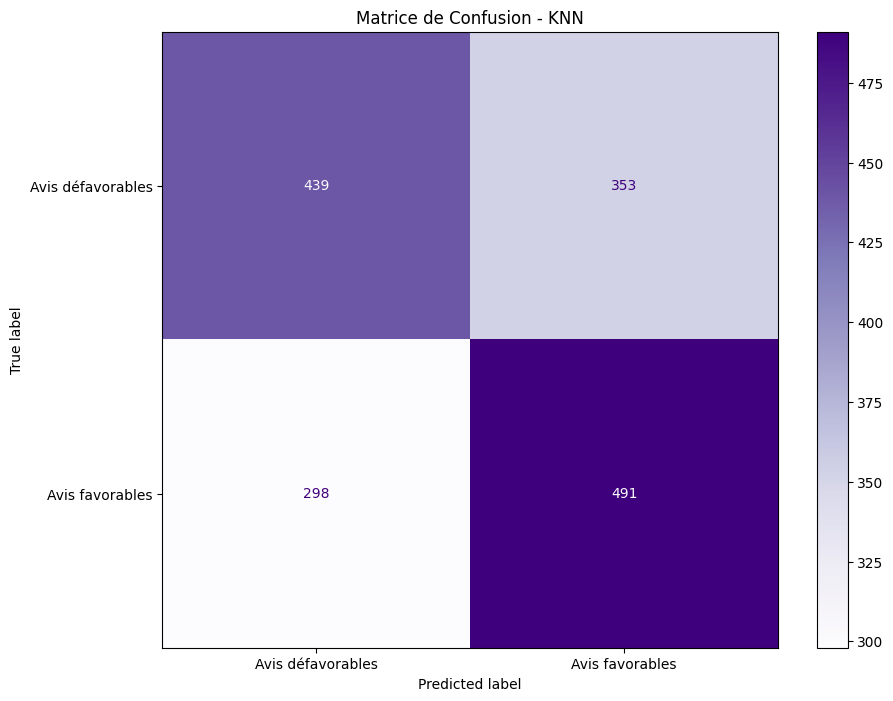

In [5]:
# --- Utilisation du classifieur KNN ---

model_tree_KNN = Pipeline([
    ('preprocessor', processeur),
    ('classifier', KNeighborsClassifier())
])

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid_KNN = {"classifier__n_neighbors" : [5, 10, 15],
                      "classifier__weights": ['uniform', 'distance'], 
                      "classifier__metric": ['euclidean', 'manhattan']}

grid_knn = GridSearchCV(model_tree_KNN, parametre_grid_KNN, cv=5, scoring='accuracy', n_jobs=-1)
grid_knn.fit(x_train, y_train)

print("Les meilleurs paramètres pour le classifieur KNN à utiliser sont : ", grid_knn.best_params_) 
print(f"Meilleur score de validation pour le classifieur KNN : {grid_knn.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model_KNN = grid_knn.best_estimator_
predictions_KNN = best_model_KNN.predict(x_test)

print("Rapport de classification pour KNN \n", classification_report(y_test, predictions_KNN, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_KNN, 
    display_labels=name_classe,
    cmap='Purples',
    ax=ax
)
plt.title("Matrice de Confusion - KNN")
plt.show()

c:\Users\Fbill\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Les meilleurs paramètres pour le classifieur Random Forest à utiliser sont :  {'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Meilleur score de validation pour le classifieur Random Forest : 0.65676 
Rapport de classification pour Random Forest 
                     precision    recall  f1-score   support

Avis défavorables       0.67      0.63      0.65       792
  Avis favorables       0.65      0.68      0.66       789

         accuracy                           0.66      1581
        macro avg       0.66      0.66      0.66      1581
     weighted avg       0.66      0.66      0.66      1581



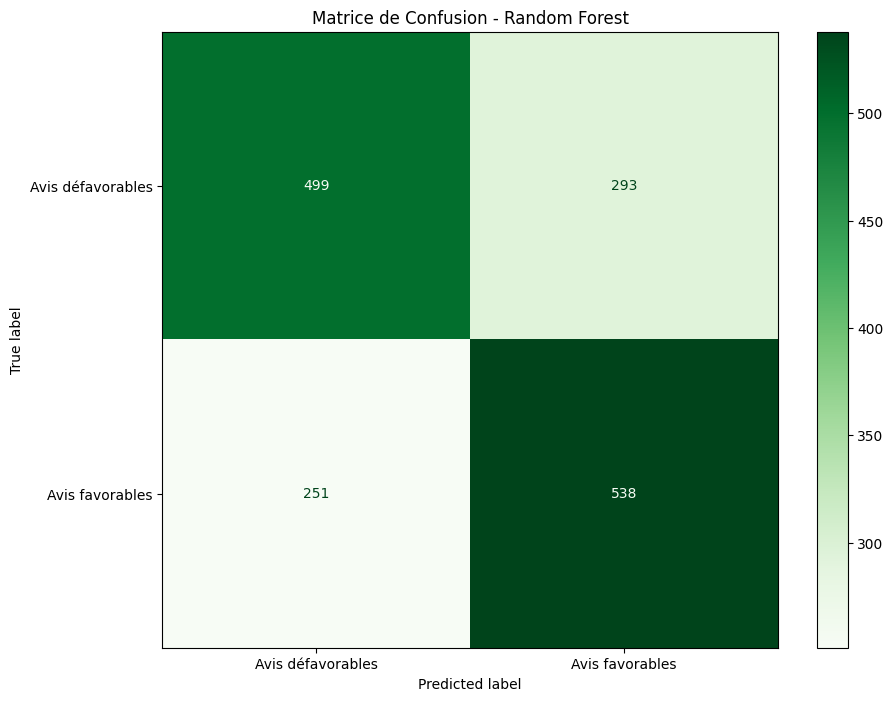

In [6]:
# --- Utilisation du classifieur Random Forest ---

model_tree_rf = Pipeline([
    ('preprocessor', processeur),
    ('classifier', RandomForestClassifier())
])

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid_rf = { 'classifier__n_estimators': [100, 200, 500],
                  "classifier__min_samples_split": [5, 10], 
                  "classifier__min_samples_leaf": [1, 2]}

grid_rf = GridSearchCV(model_tree_rf, parametre_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(x_train, y_train)

print("Les meilleurs paramètres pour le classifieur Random Forest à utiliser sont : ", grid_rf.best_params_) 
print(f"Meilleur score de validation pour le classifieur Random Forest : {grid_rf.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model_rf = grid_rf.best_estimator_
predictions_rf = best_model_rf.predict(x_test)

print("Rapport de classification pour Random Forest \n ", classification_report(y_test, predictions_rf, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_rf, 
    display_labels=name_classe,
    cmap='Greens',
    ax=ax
)
plt.title("Matrice de Confusion - Random Forest")
plt.show()

Les meilleurs paramètres pour le classifieur Logistic Regression à utiliser sont :  {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Meilleur score de validation pour le classifieur Logistic Regression : 0.65437 
Rapport de classification pour Logistic Regression 
                     precision    recall  f1-score   support

Avis défavorables       0.66      0.66      0.66       792
  Avis favorables       0.66      0.66      0.66       789

         accuracy                           0.66      1581
        macro avg       0.66      0.66      0.66      1581
     weighted avg       0.66      0.66      0.66      1581



c:\Users\Fbill\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


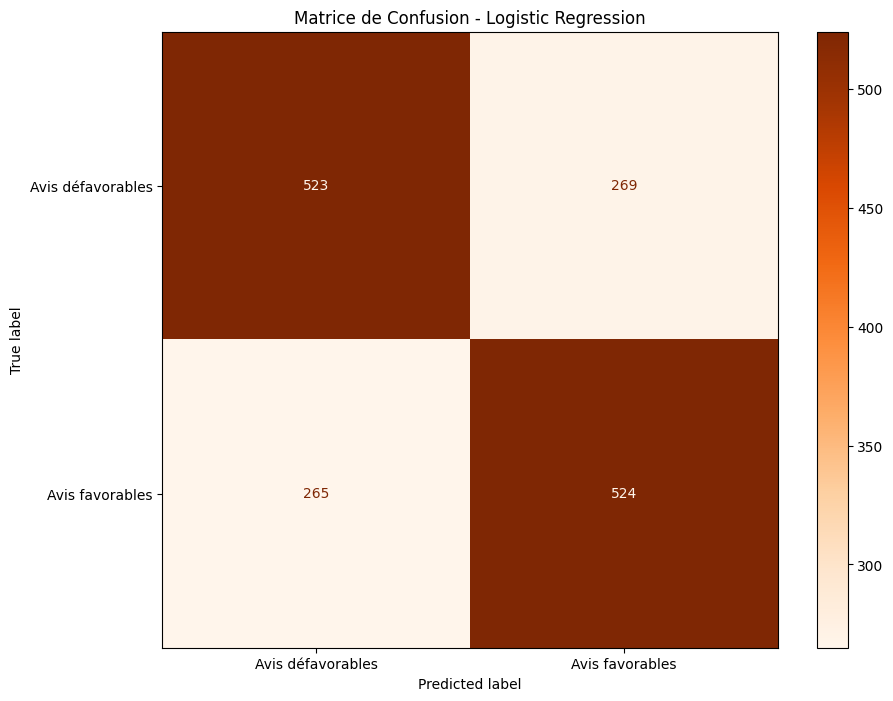

In [7]:
# --- Utilisation du classifieur Logistic Regression ---

model_tree_lr = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LogisticRegression())
])

# --- Recherche des meilleurs hypermaramètres --- 

parametre_grid_lr = { "classifier__C": [0.1, 1, 10], 
                    "classifier__solver": ['lbfgs', 'liblinear', 'newton-cg']}

grid_lr = GridSearchCV(model_tree_lr, parametre_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(x_train, y_train)

print("Les meilleurs paramètres pour le classifieur Logistic Regression à utiliser sont : ", grid_lr.best_params_) 
print(f"Meilleur score de validation pour le classifieur Logistic Regression : {grid_lr.best_score_:.5f} ")

# --- Test sur le modèle avec les meilleurs paramètres --- 

best_model_lr = grid_lr.best_estimator_
predictions_lr = best_model_lr.predict(x_test)

print("Rapport de classification pour Logistic Regression \n ", classification_report(y_test, predictions_lr, target_names=name_classe))

# --- Création de la matrice de confusion  --- 

fig, ax = plt.subplots(figsize=(10, 8)) 
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions_lr, 
    display_labels=name_classe,
    cmap='Oranges',
    ax=ax
)
plt.title("Matrice de Confusion - Logistic Regression")
plt.show()

## 3. Synthèse des expérimentations et des résultats obtenus

### Protocole d'expérimentations

Les avis ont été séparés en deux classes : 
- Avis positifs : notes strictement supérieures à 3.
- Avis négatifs : notes inférieuress ou égale à 3.

Pour chacune des expérimentations la fonction `GridSearchCV` est utilisé afin de trouver les meilleurs paramètres, elle à pour instruction de se baser sur l'`accuracy` pour trouver l'exactitude la plus haute, on utilise la validation croisée avec `5` itérations pour obtenir une moyenne avec du sens.

Une fois les meilleurs paramètres trouvés on réalise l'entrainement et les prédictions sur ces derniers, enfin on affiche les métriques et les graphiques correspondant.

### Tableaux des experimentations de paramètres pour Tfid

| Nom                        | max_features | min_df | ngram_ranges | stop_words |
| -------------------------- | ------------ | ------ | ------------ | ---------- |
| Tfid - 2000 100            | 2000         | 100    | 1,2          | english    |
| Tfid - 5000 100            | 5000         | 100    | 1,2          | english    |
| Tfid - 5000 1              | 5000         | 1      | 1,2          | english    |
| Tfid - 2000 1              | 2000         | 1      | 1,2          | english    |

Celui qui est le plus concluant est Tfid - 2000 100.

### Classifieur DecisionTree 

#### Paramètres 

| Hyperparamètres | Max_depth        | Min_samples_split | Criterion      | Splitter      |
| --------------- | ---------------- | ----------------- | -------------- | ------------- |
| Valeurs testés  | None, 10, 20, 50 | 5, 15, 20         | Gini, Entropy  | Best, Random  |
| Valeur trouvé   | 20               | 15                | Entropy        | Best          |

Ces hyperparamètres permettent de trouver une excactitude de 0.60.

### Classifieur KNN 

#### Paramètres 

parametre_grid_KNN = {"classifier__n_neighbors" : [5, 10, 15],
                      "classifier__weights": ['uniform', 'distance'], 
                      "classifier__metric": ['euclidean', 'manhattan']}

| Hyperparamètres | N_neighbors      | Weights           | Metric                |
| --------------- | ---------------- | ----------------- | --------------------- |
| Valeurs testés  | 5, 10, 15        | Uniform, Distance | Euclidean, Manhattan  |
| Valeur trouvé   | 15               | Uniform           | Euclidean             |

Ces hyperparamètres permettent de trouver une excactitude de 0.59.


# Partie bonus

Dans cette partie nous avons utilisé le classifieur `Random Forest` et `Logistic Regression`

### Classifieur Random Forest 

#### Paramètres 

| Hyperparamètres | Min_samples_leaf | Min_samples_split | N_estimators   |
| --------------- | ---------------- | ----------------- | -------------- |
| Valeurs testés  | 1, 2             | 5, 10             | 100, 200, 500  |
| Valeur trouvé   | 2                | 5                 | 200            |

Ces hyperparamètres permettent de trouver une excactitude de 0.66.

### Classifieur Logistic Regression 

#### Paramètres 

| Hyperparamètres | C          | Solver                      |
| --------------- | -----------| --------------------------- |
| Valeurs testés  | 0.1, 1, 10 | Lbfgs, Liblinear, Newton-cg |
| Valeur trouvé   | 1          | Lbfgs                       |

Ces hyperparamètres permettent de trouver une excactitude de 0.66.

---

**Conclusion**:

Les différentes expérimentations ont permis de comparer plusieurs approches de classification binaire. 

Dans les classifieurs vu en cours celui qui a été le plus performant est Decision Tree avec 0.60 d'exactitude.

Et parmis les classifieurs bonus qui sont Random Forest et Logistic Regression, les deux atteignent une excatitude de 0.66. 

Ainsi les classifieurs les plus performants pour ce jeu de données sont Random Forest ou le Logistic Regression. 

Pour améliorer cette excactitude, il faudrait avoir plus de données et mieux répartis. Une autre solution d'amélioration serait également de pousser les pré-traitements des avis.